In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/ordenes.csv")

X = df["descripcion_falla"]
y = df["categoria_falla"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print(y.value_counts())

Entrenamiento: 3200 | Prueba: 800
categoria_falla
software              881
pantalla              494
disco_duro            419
sobrecalentamiento    380
cabezal_tinta         332
bateria               320
atasco_papel          302
teclado_touchpad      260
placa_madre           231
fuente_poder          194
fusor_laser           187
Name: count, dtype: int64


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

modelo_base = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000)),
])

modelo_base.fit(X_train, y_train)
pred = modelo_base.predict(X_test)

print(classification_report(y_test, pred))

                    precision    recall  f1-score   support

      atasco_papel       1.00      0.97      0.98        61
           bateria       0.98      0.98      0.98        64
     cabezal_tinta       1.00      0.95      0.98        66
        disco_duro       0.94      0.93      0.93        84
      fuente_poder       0.95      0.92      0.94        39
       fusor_laser       1.00      0.97      0.99        37
          pantalla       0.86      0.97      0.91        99
       placa_madre       1.00      0.93      0.97        46
sobrecalentamiento       0.99      0.92      0.95        76
          software       0.95      0.98      0.96       176
  teclado_touchpad       0.98      0.94      0.96        52

          accuracy                           0.96       800
         macro avg       0.97      0.95      0.96       800
      weighted avg       0.96      0.96      0.96       800



In [3]:
frases = [
    "mi laptop no enciende y huele a quemado",
    "la impresora jala dos hojas a la vez",
    "se me cayo agua en el teclado",
    "esta muy lenta y sale pantalla azul",
    "me hace ruido fuerte y se calienta mucho",
]

for f in frases:
    probs = modelo_base.predict_proba([f])[0]
    top = probs.argsort()[::-1][:2]
    sugerencias = ", ".join(f"{modelo_base.classes_[i]} ({probs[i]:.0%})" for i in top)
    print(f"{f}\n   -> {sugerencias}\n")

mi laptop no enciende y huele a quemado
   -> placa_madre (53%), fuente_poder (15%)

la impresora jala dos hojas a la vez
   -> atasco_papel (87%), pantalla (3%)

se me cayo agua en el teclado
   -> teclado_touchpad (77%), bateria (4%)

esta muy lenta y sale pantalla azul
   -> software (89%), disco_duro (3%)

me hace ruido fuerte y se calienta mucho
   -> sobrecalentamiento (63%), fusor_laser (7%)



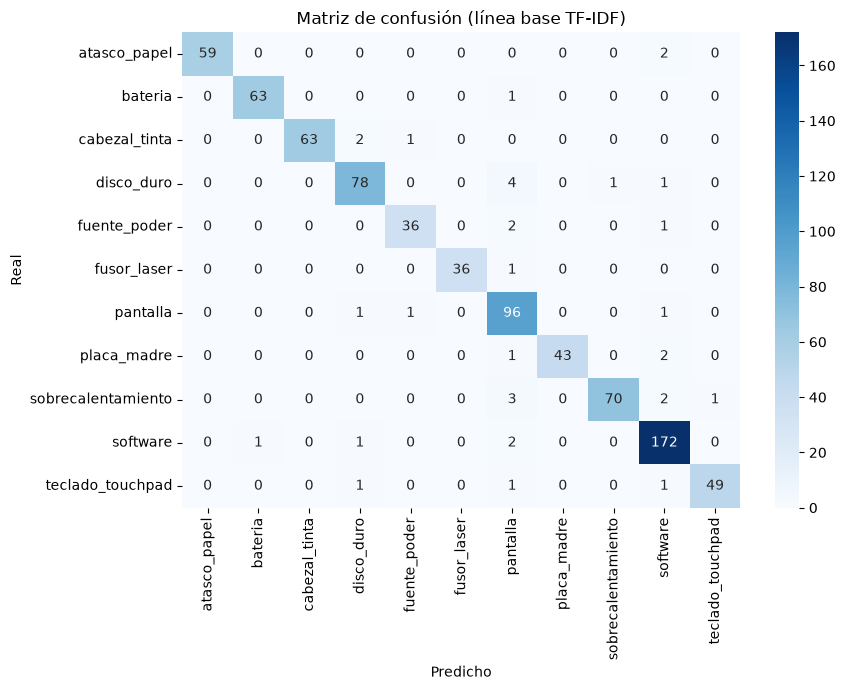

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

clases = modelo_base.classes_
cm = confusion_matrix(y_test, pred, labels=clases)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=clases, yticklabels=clases)
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.title("Matriz de confusión (línea base TF-IDF)")
plt.tight_layout()
plt.show()

In [5]:
errores = pd.DataFrame({"texto": X_test, "real": y_test, "predicho": pred})
errores = errores[errores["real"] != errores["predicho"]]
print("Total de errores:", len(errores))
errores.head(15)

Total de errores: 35


,texto,real,predicho
1347,"hola, falla de repente",sobrecalentamiento,teclado_touchpad
3709,no funciona bien desde ayer,atasco_papel,software
507,no anda como antes,fuente_poder,software
3727,NO FUNCIONA BIEN,cabezal_tinta,disco_duro
1498,falla de repenet,teclado_touchpad,software
3412,urgente: no anda como antees,pantalla,fuente_poder
3332,tiene un problema pero no se que es,placa_madre,pantalla
649,"bueenos dias, no anda como antes",sobrecalentamiento,software
1799,mi equipo: tiene un problema pero no se que es,sobrecalentamiento,pantalla
2478,no anda como antes,placa_madre,software


In [7]:
prueba = pd.read_csv("../data/prueba_manual.csv", skipinitialspace=True)
prueba["categoria"] = prueba["categoria"].str.strip()

pred_manual = modelo_base.predict(prueba["texto"])
aciertos = (pred_manual == prueba["categoria"]).mean()
print(f"Exactitud en prueba manual (TF-IDF): {aciertos:.0%}  ({(pred_manual == prueba['categoria']).sum()} de {len(prueba)})")

fallos = prueba.assign(predicho=pred_manual)
fallos[fallos["categoria"] != fallos["predicho"]]

Exactitud en prueba manual (TF-IDF): 48%  (14 de 29)


,texto,categoria,predicho
0,mi laptop quedó muerta después del apagón de ayer,placa_madre,bateria
4,se quebró el vidrio del monitor de la laptop,pantalla,bateria
5,la compu tarda una eternidad en arrancar y hac...,disco_duro,pantalla
7,se borraron mis documentos y no puedo abrir nada,disco_duro,placa_madre
8,la torre no da señales de vida ni luces ni ruido,fuente_poder,placa_madre
9,al encenderla escuché un estallido y se fue la...,fuente_poder,placa_madre
10,se reinicia sola cada vez que le exijo,sobrecalentamiento,atasco_papel
11,el aire que sale de la laptop quema y el venti...,sobrecalentamiento,atasco_papel
16,el cursor salta de un lado a otro sin que lo t...,teclado_touchpad,disco_duro
17,derramé jugo sobre el teclado,teclado_touchpad,bateria
